In [13]:
import pandas as pd
import matplotlib.pyplot as plt


In [15]:
def cargarCSV(ruta):
    nombre_columnas = ['FECHA', 'PRECIP', 'EVAP', 'TMAX', 'TMIN']
    df = pd.read_csv('25001.txt',
               sep='\s+',
               skiprows=19,
               names=nombre_columnas,
               na_values=['Nulo'],
               encoding='latin1'      #Se usa encoding='latin1' para evitar errores con caracteres en español 
              )
    return df

    


<>:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\robbm\AppData\Local\Temp\ipykernel_50784\2249629648.py:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  sep='\s+',


In [16]:
# Llamamos a la función y guardamos los datos en la variable 'df'
df = cargarCSV('25001.txt')

#Mostramos la tabla
print("\n--- Vista de la tabla---")
print(df.head())

#Un  describe para ver las estadística
print("\n--- Nuevo Resumen Estadístico---")
print(df.describe())


--- Vista de la tabla---
        FECHA  PRECIP  EVAP  TMAX  TMIN
0  01/01/1961     0.0   NaN  25.0  13.0
1  02/01/1961     0.0   NaN  27.5  14.0
2  03/01/1961     0.0   NaN  31.0  11.0
3  04/01/1961     0.0   NaN  32.0  13.0
4  05/01/1961     0.0   NaN  29.0  14.0

--- Nuevo Resumen Estadístico---
             PRECIP          EVAP          TMAX          TMIN
count  19534.000000  19302.000000  19569.000000  19568.000000
mean       2.217452      4.882157     34.468808     16.657420
std        9.015782      2.279340      3.430054      6.248605
min        0.000000      0.000000     18.000000     -2.500000
25%        0.000000      3.200000     32.500000     11.000000
50%        0.000000      4.500000     35.000000     16.500000
75%        0.000000      6.500000     37.000000     23.000000
max      217.400000     15.600000     45.500000     29.000000


In [17]:
#Contar cuantos Nulos hay en fecha
def contarNulos(df):
    print("---Conteo de Registros faltantes por fecha---")
    faltantes={}
    
    for indice,fila in df.iterrows():
        if fila.isnull().any():
            cantidad_nulos=fila.isnull().sum()
            fecha=fila['FECHA']
            faltantes[fecha]=cantidad_nulos
    
    print(f"Se encontraron {len(faltantes)} fechas con datos faltantes.")
    print("Ejemplo de las primeras 5 fechas:")
    for fecha in list(faltantes.keys())[:5]:
        print(f"Fecha: {fecha} | Faltantes: {faltantes[fecha]}")
    
   

In [18]:
def limpiar_datos(df):
    print("Rellenando nulos con la media de la columna")
    
    df_limpio=df.copy()
    columnas_numericas=['PRECIP','EVAP','TMAX','TMIN']
    
    for columna in columnas_numericas:
        media_columna=df_limpio[columna].mean()
        df_limpio[columna] = df_limpio[columna].fillna(media_columna)
        print(f"Columna '{columna}': nulos reemplazados con la media -> {media_columna:.2f} ")
    return df_limpio


In [28]:
def graficar_histogramas_y_boxplots(df_original, df_limpio):
    """Compara la limpieza con dos histogramas y un boxplot."""

    # Histogramas de PRECIP y EVAP: muestran cómo cambia su distribución.
    for columna in ['PRECIP', 'EVAP']:
        fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

        ejes[0].hist(df_original[columna].dropna(), bins=20, edgecolor='black')
        ejes[0].set_title(f'Histograma antes: {columna}')
        ejes[0].set_xlabel(columna)
        ejes[0].set_ylabel('Frecuencia')

        ejes[1].hist(df_limpio[columna].dropna(), bins=20, edgecolor='black')
        ejes[1].set_title(f'Histograma después: {columna}')
        ejes[1].set_xlabel(columna)
        ejes[1].set_ylabel('Frecuencia')

        fig.tight_layout()
        plt.show()

    # Boxplot de TMAX: permite comparar la dispersión y valores atípicos.
    plt.figure(figsize=(7, 4))
    plt.boxplot(
        [df_original['TMAX'].dropna(), df_limpio['TMAX'].dropna()],
        tick_labels=['Antes', 'Después']
    )
    plt.title('Boxplot antes y después: TMAX')
    plt.ylabel('TMAX (°C)')
    plt.show()


In [20]:
df_lleno = limpiar_datos(df)

#Mostramos la tabla DESPUÉS de llenar
print("\n--- Vista de la tabla DESPUÉS de llenar ---")
print(df_lleno.head())

#Un nuevo describe para ver como cambió la estadística
print("\n--- Nuevo Resumen Estadístico (Post-Limpieza) ---")
print(df_lleno.describe())

Rellenando nulos con la media de la columna
Columna 'PRECIP': nulos reemplazados con la media -> 2.22 
Columna 'EVAP': nulos reemplazados con la media -> 4.88 
Columna 'TMAX': nulos reemplazados con la media -> 34.47 
Columna 'TMIN': nulos reemplazados con la media -> 16.66 

--- Vista de la tabla DESPUÉS de llenar ---
        FECHA  PRECIP      EVAP  TMAX  TMIN
0  01/01/1961     0.0  4.882157  25.0  13.0
1  02/01/1961     0.0  4.882157  27.5  14.0
2  03/01/1961     0.0  4.882157  31.0  11.0
3  04/01/1961     0.0  4.882157  32.0  13.0
4  05/01/1961     0.0  4.882157  29.0  14.0

--- Nuevo Resumen Estadístico (Post-Limpieza) ---
             PRECIP          EVAP          TMAX          TMIN
count  19575.000000  19575.000000  19575.000000  19575.000000
mean       2.217452      4.882157     34.468808     16.657420
std        9.006335      2.263389      3.429528      6.247488
min        0.000000      0.000000     18.000000     -2.500000
25%        0.000000      3.200000     32.500000     11

--- Histogramas y boxplots antes y después de la limpieza ---


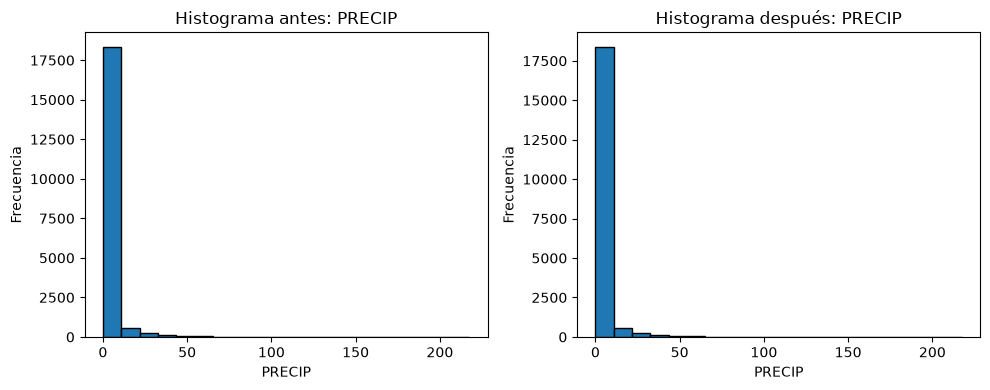

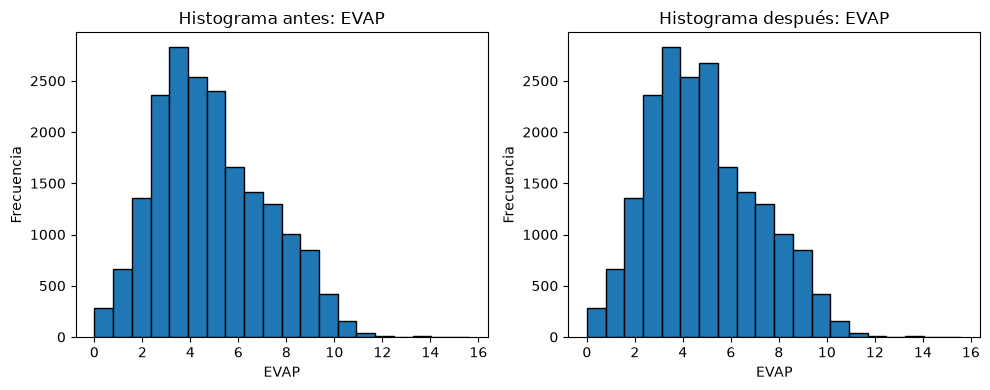

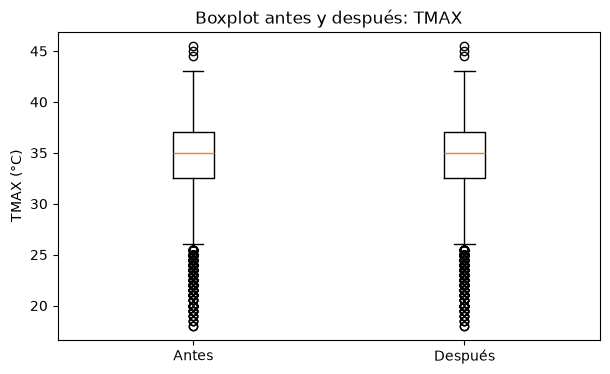

In [29]:
# Comparación visual antes y después de la limpieza
print("--- Histogramas y boxplots antes y después de la limpieza ---")
graficar_histogramas_y_boxplots(df, df_lleno)


In [33]:
def main():
    archivo='25001.txt'
    datos=cargarCSV(archivo)
    contarNulos(datos)
    datos_limpios = limpiar_datos(datos)


In [34]:
if __name__ == "__main__":
    main()

---Conteo de Registros faltantes por fecha---
Se encontraron 313 fechas con datos faltantes.
Ejemplo de las primeras 5 fechas:
Fecha: 01/01/1961 | Faltantes: 1
Fecha: 02/01/1961 | Faltantes: 1
Fecha: 03/01/1961 | Faltantes: 1
Fecha: 04/01/1961 | Faltantes: 1
Fecha: 05/01/1961 | Faltantes: 1
Rellenando nulos con la media de la columna
Columna 'PRECIP': nulos reemplazados con la media -> 2.22 
Columna 'EVAP': nulos reemplazados con la media -> 4.88 
Columna 'TMAX': nulos reemplazados con la media -> 34.47 
Columna 'TMIN': nulos reemplazados con la media -> 16.66 
